# MonReader Notebook

Background:

Our company develops innovative Artificial Intelligence and Computer Vision solutions that revolutionize industries. Machines that can see: We pack our solutions in small yet intelligent devices that can be easily integrated to your existing data flow. Computer vision for everyone: Our devices can recognize faces, estimate age and gender, classify clothing types and colors, identify everyday objects and detect motion. Technical consultancy: We help you identify use cases of artificial intelligence and computer vision in your industry. Artificial intelligence is the technology of today, not the future.

MonReader is a new mobile document digitization experience for the blind, for researchers and for everyone else in need for fully automatic, highly fast and high-quality document scanning in bulk. It is composed of a mobile app and all the user needs to do is flip pages and everything is handled by MonReader: it detects page flips from low-resolution camera preview and takes a high-resolution picture of the document, recognizing its corners and crops it accordingly, and it dewarps the cropped document to obtain a bird's eye view, sharpens the contrast between the text and the background and finally recognizes the text with formatting kept intact, being further corrected by MonReader's ML powered redactor.



MonReader is a new mobile document digitalization experience for the blind, for researchers and for everyone else in need for fully automatic, highly fast and high-quality document scanning in bulk. It is composed of a mobile app and all the user needs to do is flip pages and everything is handled by MonReader: it detects page flips from low-resolution camera preview and takes a high-resolution picture of the document, recognizing its corners and crops it accordingly, and it dewarps the cropped document to obtain a bird's eye view, sharpens the contrast between the text and the background and finally recognizes the text with formatting kept intact, being further corrected by MonReader's ML powered redactor.




Goal(s):

Predict if the page is being flipped using a single image.

Success Metrics:

Evaluate model performance based on F1 score, the higher the better.

Current Challenges:

Predict if a given sequence of images contains an action of flipping.

### Data Extraction + EDA

In [2]:
import os
import zipfile
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

random.seed(42)
np.random.seed(42)

ZIP_PATH = Path("data/images.zip")
EXTRACT_DIR = Path("data")

In [3]:
# Extract only if not already done
if not (EXTRACT_DIR / "images").exists():
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(EXTRACT_DIR)
    print("Extracted.")
else:
    print("Already extracted.")

Already extracted.


In [4]:
# Load DataFrame of image paths and metadata
DATA_ROOT = EXTRACT_DIR / "images"

records = []
for img_path in DATA_ROOT.rglob("*"):
    if img_path.suffix.lower() in {".jpg", ".jpeg", ".png"}:
        parts = [p.lower() for p in img_path.parts]
        split = "training" if "training" in parts else ("testing" if "testing" in parts else "unknown")
        label = img_path.parent.name.lower()          # e.g. 'flip' or 'notflip'
        stem = img_path.stem                          # VideoID_FrameNumber
        video_id, _, frame_no = stem.rpartition("_")
        records.append({
            "path": str(img_path),
            "split": split,
            "label": label,
            "video_id": video_id,
            "frame_no": int(frame_no) if frame_no.isdigit() else -1,
        })

df = pd.DataFrame(records)
print(df.shape)
df.head()

(2989, 5)


,path,split,label,video_id,frame_no
0,data\images\testing\flip\0001_000000020.jpg,testing,flip,0001,20
1,data\images\testing\flip\0002_000000012.jpg,testing,flip,0002,12
2,data\images\testing\flip\0002_000000013.jpg,testing,flip,0002,13
3,data\images\testing\flip\0002_000000015.jpg,testing,flip,0002,15
4,data\images\testing\flip\0002_000000017.jpg,testing,flip,0002,17


label     flip  notflip
split                  
testing    290      307
training  1162     1230


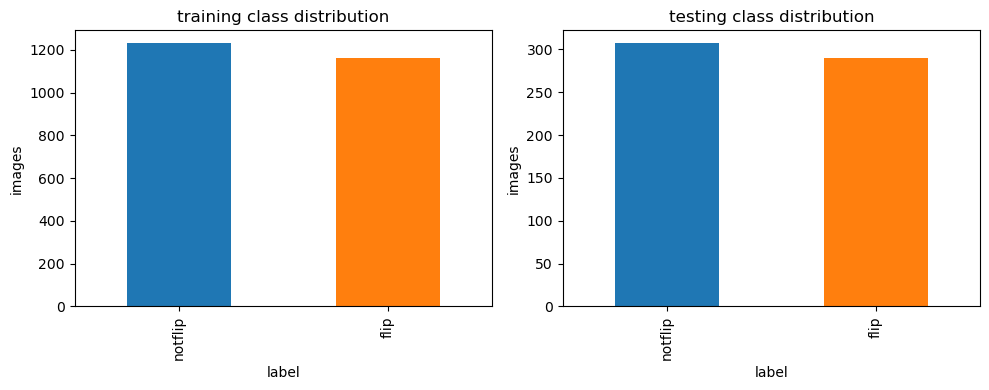

In [5]:
# Show class distribution in training and testing sets
print(df.groupby(["split", "label"]).size().unstack(fill_value=0))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, split in zip(axes, ["training", "testing"]):
    sub = df[df.split == split]
    sub["label"].value_counts().plot(kind="bar", ax=ax, color=["tab:blue", "tab:orange"])
    ax.set_title(f"{split} class distribution")
    ax.set_ylabel("images")
plt.tight_layout()
plt.show()

In [6]:
# How many distinct videos, and frames per video? (important for avoiding leakage later)
print("Unique videos per split:")
print(df.groupby("split")["video_id"].nunique())

frames_per_video = df.groupby(["split", "video_id"]).size()
print("\nFrames per video:")
print(frames_per_video.describe())

Unique videos per split:
split
testing     65
training    65
Name: video_id, dtype: int64

Frames per video:
count    130.000000
mean      22.992308
std       16.281676
min        1.000000
25%        9.000000
50%       16.000000
75%       39.000000
max       56.000000
dtype: float64


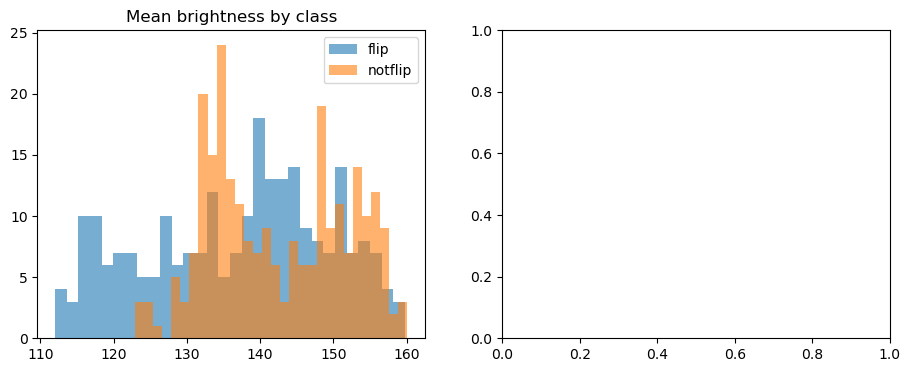

In [7]:
# Sample a subset of images for analysis
sample = df.sample(min(500, len(df)), random_state=42)

sizes, brightness = [], []
for p in sample.path:
    with Image.open(p) as im:
        sizes.append(im.size)  # (width, height)
        brightness.append(np.asarray(im.convert("L")).mean())

sample = sample.assign(
    width=[s[0] for s in sizes],
    height=[s[1] for s in sizes],
    brightness=brightness,
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for lbl, g in sample.groupby("label"):
    axes[0].hist(g.brightness, bins=30, alpha=0.6, label=lbl)
axes[0].set_title("Mean brightness by class")
axes[0].legend()


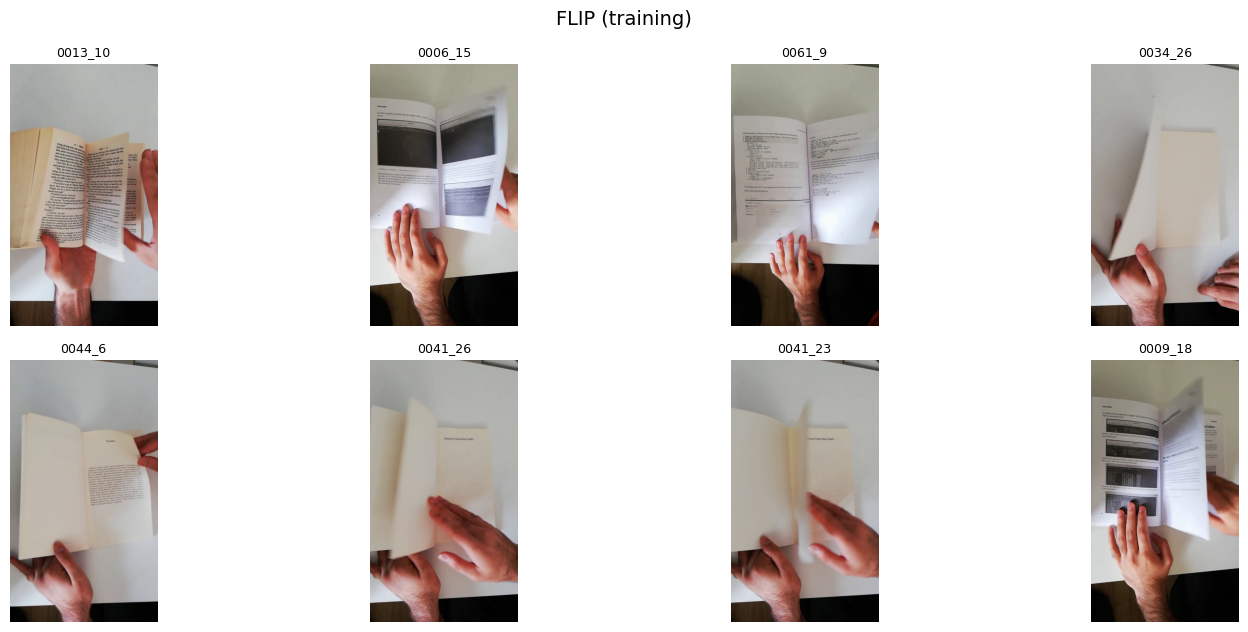

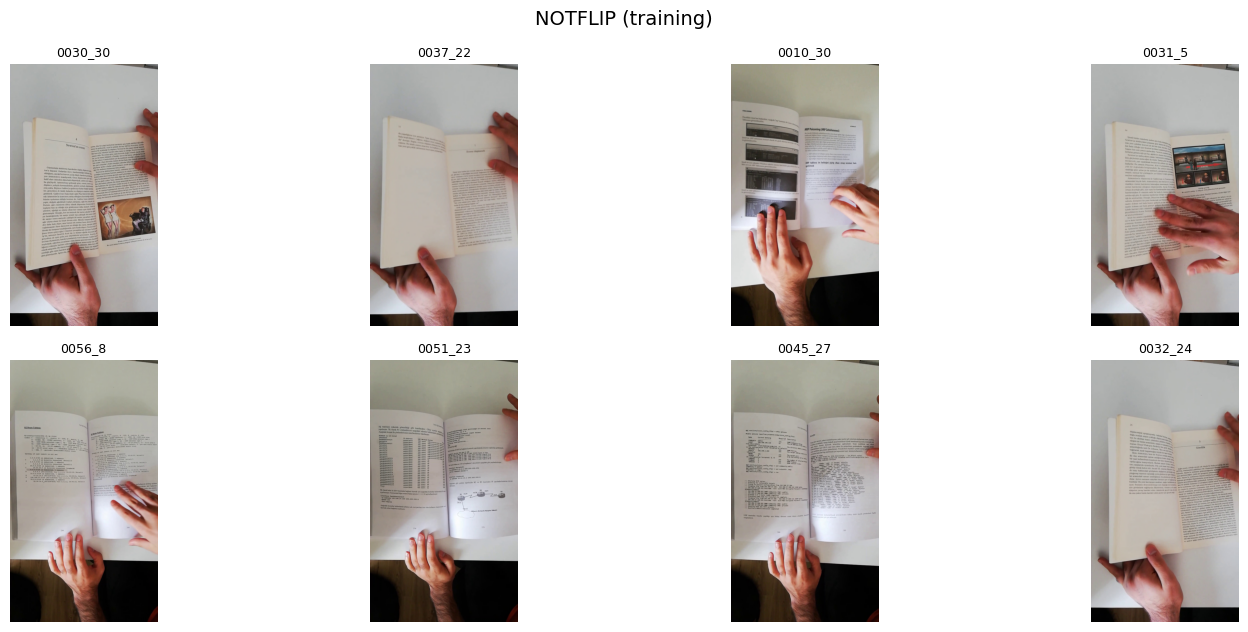

In [8]:
# Show a few sample images for each class
def show_samples(df, label, n=8, split="training"):
    subset = df[(df.label == label) & (df.split == split)]
    picks = subset.sample(min(n, len(subset)), random_state=42)
    cols = 4
    rows = int(np.ceil(len(picks) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3.2 * rows))
    axes = np.array(axes).reshape(-1)
    for ax, (_, row) in zip(axes, picks.iterrows()):
        ax.imshow(Image.open(row.path))
        ax.set_title(f"{row.video_id}_{row.frame_no}", fontsize=9)
        ax.axis("off")
    for ax in axes[len(picks):]:
        ax.axis("off")
    fig.suptitle(f"{label.upper()} ({split})", fontsize=14)
    plt.tight_layout()
    plt.show()

for lbl in sorted(df.label.unique()):
    show_samples(df, lbl)

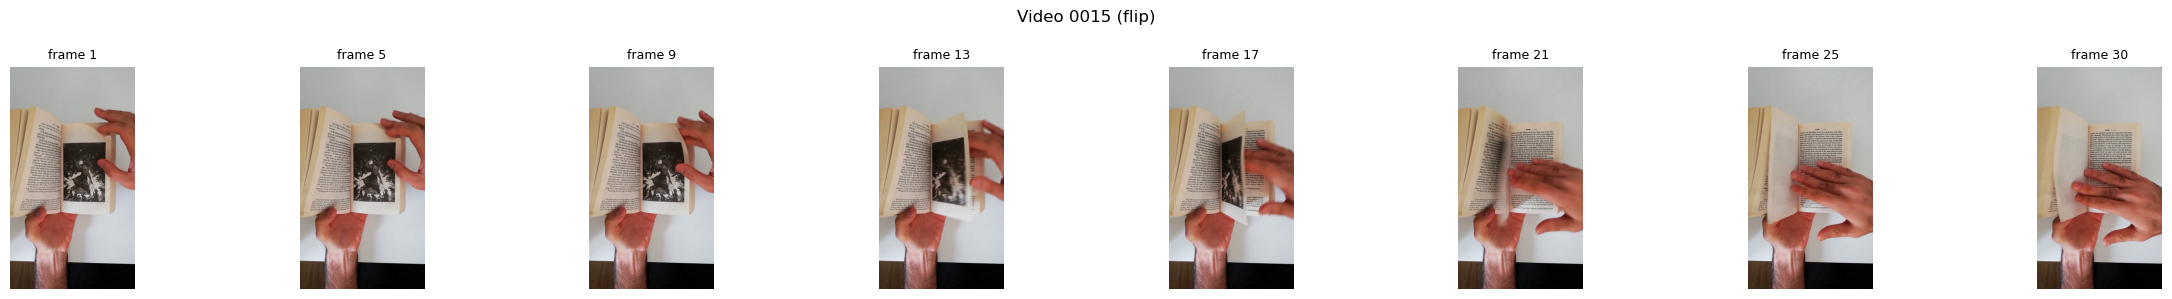

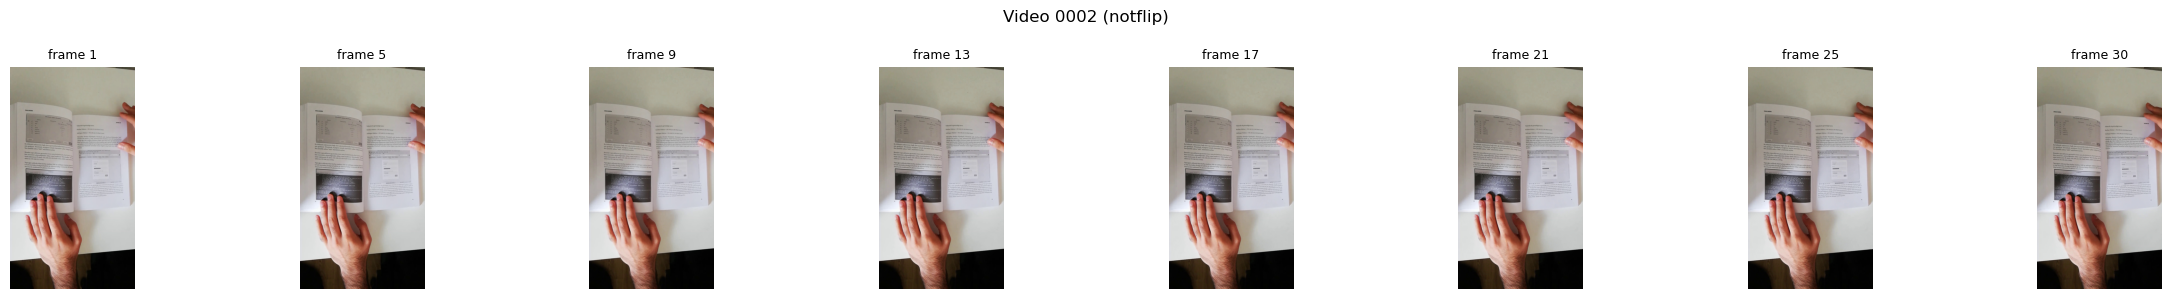

In [9]:
# Frames are sequential within a video, so this shows what a flip looks like over time
def show_video_sequence(df, label, n_frames=8):
    vid = random.choice(df[df.label == label].video_id.unique())
    seq = df[(df.video_id == vid) & (df.label == label)].sort_values("frame_no")
    idx = np.linspace(0, len(seq) - 1, min(n_frames, len(seq))).astype(int)
    picks = seq.iloc[idx]

    fig, axes = plt.subplots(1, len(picks), figsize=(3 * len(picks), 3))
    axes = np.atleast_1d(axes)
    for ax, (_, row) in zip(axes, picks.iterrows()):
        ax.imshow(Image.open(row.path))
        ax.set_title(f"frame {row.frame_no}", fontsize=9)
        ax.axis("off")
    fig.suptitle(f"Video {vid} ({label})")
    plt.tight_layout()
    plt.show()

for lbl in sorted(df.label.unique()):
    show_video_sequence(df, lbl)

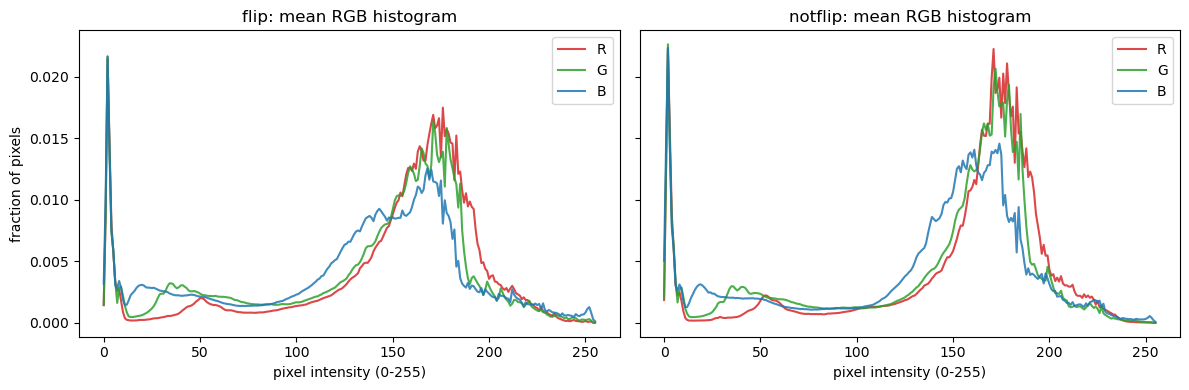

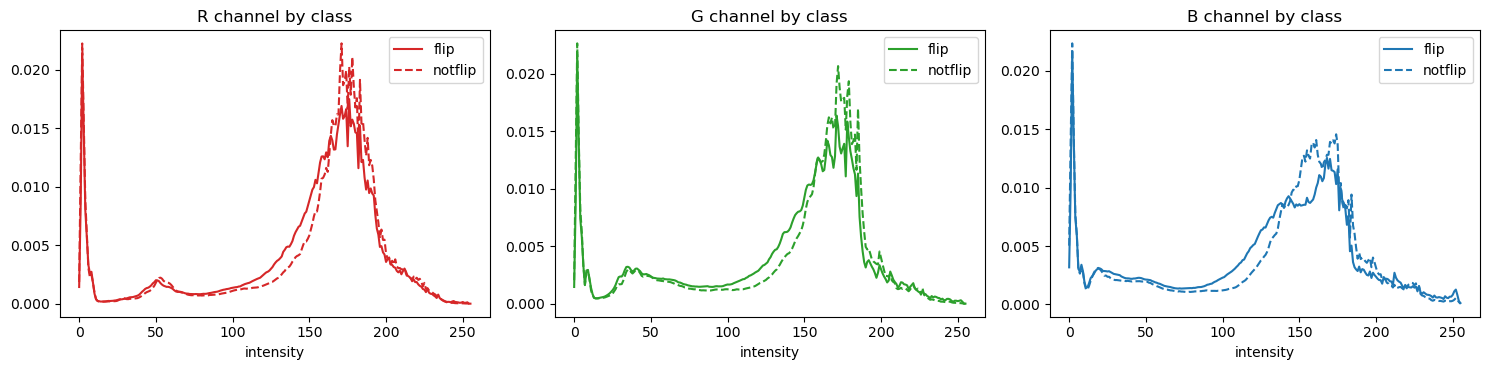

Mean RGB per class:
             R      G      B
flip     147.5  134.5  127.6
notflip  151.2  139.2  132.3


In [10]:
def load_rgb(path, size=(224, 224)):
    return np.asarray(Image.open(path).convert("RGB").resize(size))

N_PER_CLASS = 300
labels = sorted(df.label.unique())
colours = {"R": "tab:red", "G": "tab:green", "B": "tab:blue"}

hist_store, mean_rgb = {}, {}
for lbl in labels:
    picks = df[df.label == lbl].sample(min(N_PER_CLASS, (df.label == lbl).sum()), random_state=42)
    hists = np.zeros((3, 256))
    means = []
    for p in picks.path:
        arr = load_rgb(p)
        for c in range(3):
            hists[c] += np.bincount(arr[..., c].ravel(), minlength=256)
        means.append(arr.reshape(-1, 3).mean(0))
    hists /= hists.sum(axis=1, keepdims=True)          # normalise to a distribution
    hist_store[lbl] = hists
    mean_rgb[lbl] = np.mean(means, axis=0)

# Per-class RGB histograms
fig, axes = plt.subplots(1, len(labels), figsize=(6 * len(labels), 4), sharey=True)
axes = np.atleast_1d(axes)
for ax, lbl in zip(axes, labels):
    for c, (name, col) in enumerate(colours.items()):
        ax.plot(hist_store[lbl][c], color=col, label=name, alpha=0.85)
    ax.set_title(f"{lbl}: mean RGB histogram")
    ax.set_xlabel("pixel intensity (0-255)")
    ax.legend()
axes[0].set_ylabel("fraction of pixels")
plt.tight_layout()
plt.show()

# Direct overlay per channel, so class differences are easy to see
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for c, (name, col) in enumerate(colours.items()):
    for lbl, ls in zip(labels, ["-", "--"]):
        axes[c].plot(hist_store[lbl][c], color=col, linestyle=ls, label=lbl)
    axes[c].set_title(f"{name} channel by class")
    axes[c].set_xlabel("intensity")
    axes[c].legend()
plt.tight_layout()
plt.show()

print("Mean RGB per class:")
print(pd.DataFrame(mean_rgb, index=["R", "G", "B"]).T.round(1))

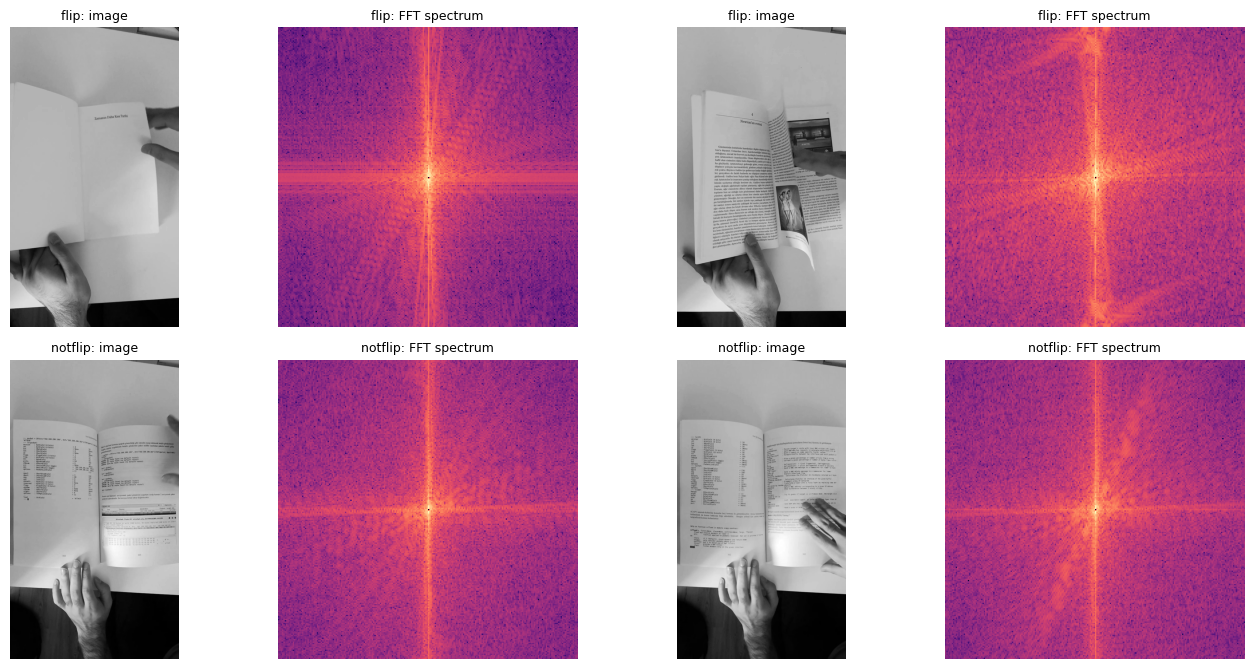

In [11]:
def fft_spectrum(path, size=(224, 224)):
    gray = np.asarray(Image.open(path).convert("L").resize(size), dtype=np.float32)
    gray -= gray.mean()
    f = np.fft.fftshift(np.fft.fft2(gray))
    return np.log1p(np.abs(f))                          # log magnitude for visibility

fig, axes = plt.subplots(len(labels), 4, figsize=(14, 3.4 * len(labels)))
for r, lbl in enumerate(labels):
    picks = df[df.label == lbl].sample(2, random_state=7)
    for k, (_, row) in enumerate(picks.iterrows()):
        axes[r, 2 * k].imshow(Image.open(row.path).convert("L"), cmap="gray")
        axes[r, 2 * k].set_title(f"{lbl}: image", fontsize=9)
        axes[r, 2 * k + 1].imshow(fft_spectrum(row.path), cmap="magma")
        axes[r, 2 * k + 1].set_title(f"{lbl}: FFT spectrum", fontsize=9)
        axes[r, 2 * k].axis("off"); axes[r, 2 * k + 1].axis("off")
plt.tight_layout()
plt.show()

## Discussion: Data Exploration

### Dataset overview

The dataset has 2,989 frames: 2,392 for training and 597 for testing. The classes are almost perfectly balanced (training: 1,162 flip / 1,230 notflip; test: 290 flip / 307 notflip), so accuracy is not misleading, and F1 on the flip class remains the success metric. Frames come from 65 video IDs per split, with 1 to 56 frames per video (median 16).

### Shared recordings between train and test

All 65 video IDs appear in both the training and test folders, and 50 of the test video IDs contain both classes. This suggests that a video ID is a source recording cut into several short clips, each labelled flip or notflip, with different clips landing in each split. A check confirmed that no individual frame appears in both splits, so the test frames are distinct. However, test clips still share their book, lighting and camera position with training clips, so a model can partly learn the scene as well as the flipping action, and test scores may be somewhat optimistic for new recordings. Validation was split from the training data by video ID, so it contains unseen recordings, which makes it the stricter estimate and a plausible reason why validation F1 was sometimes lower than test F1 later in the notebook. Because most videos contain both classes, video-level labels are also not clean, which matters for the sequence-level challenge.

### What the images show

All frames are portrait, top-down views of an open book on a white desk, with hands visible. Flip frames show a lifted or curved page, often with motion blur on the page and hand. Notflip frames show flat, sharp pages with hands resting on the book. Hands appear in both classes, so they are not a useful cue; page shape and sharpness are the informative signals.

The sequences show that the first frames of a flip clip look static and only later frames show the page moving, so frames at the start and end of a flip may be hard to tell from notflip. Notflip clips are almost identical from frame to frame, so consecutive frames are near-duplicates and the effective number of independent examples is much smaller than the frame count.

### Colour, brightness and frequency content

Flip frames are slightly darker on average (mean RGB 147.5, 134.5, 127.6 against 151.2, 139.2, 132.3 for notflip), but the colour histograms overlap heavily. The difference is probably due to shadows from the moving page and hand or to clip-level lighting, so colour is a weak cue at best. The FFT spectra of four examples showed no clear difference between classes. Motion blur removing high-frequency detail is plausible but was not confirmed quantitatively.

### Implications for modelling

- Pretrained CNN backbones are a reasonable starting point, since the useful cues (page curvature, blur, edges) are generic visual features.
- Avoid blur-based augmentation, because motion blur is likely a real flip cue.
- Split validation by video ID, because frames within a video are near-duplicates.
- Compare models under identical conditions, and treat any single test score cautiously given the shared recordings.
- Expect some unavoidable error from ambiguous frames at the start and end of a flip.

### Limitations

Brightness and colour statistics came from samples of 300 to 500 images, the FFT used four examples, and only one sequence per class was inspected. Image dimensions, corrupt files and differences between individual recordings were not examined.

## Baseline Models

### ResNet50 Baseline

In [12]:
print(df.split.value_counts())

def assign_split(path_str):
    parts = [p.lower() for p in Path(path_str).relative_to(DATA_ROOT).parts]
    if any(p in {"train", "training"} for p in parts):
        return "training"
    if any(p in {"test", "testing"} for p in parts):
        return "testing"
    return "unknown"

df["split"] = df.path.apply(assign_split)
print(df.groupby(["split", "label"]).size().unstack(fill_value=0))
assert (df.split == "unknown").sum() == 0, "Some images are unassigned, check your folder names"

split
training    2392
testing      597
Name: count, dtype: int64
label     flip  notflip
split                  
testing    290      307
training  1162     1230


In [13]:
import json, time
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from sklearn.model_selection import GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score, classification_report, confusion_matrix

keras.utils.set_random_seed(42)

# ---- Speed settings: scale up for a final run ----
IMG_SIZE = (160, 160)      # (224, 224) for the final run
BATCH = 64                 # drop to 32 or 16 if you run out of memory
FRAME_STEP = 2             # keep every 2nd frame for train/val (1 = all frames)
HEAD_EPOCHS = 3
FT_EPOCHS = 4
UNFREEZE_LAYERS = 20
# ---------------------------------------------------
AUTOTUNE = tf.data.AUTOTUNE

gpus = tf.config.list_physical_devices("GPU")
print("TF", tf.__version__, "| GPUs:", gpus)
if gpus:
    keras.mixed_precision.set_global_policy("mixed_float16")

labels_found = sorted(df.label.unique())
assert "flip" in labels_found, f"Expected a 'flip' folder, found {labels_found}"
LABEL_MAP = {lbl: (1 if lbl == "flip" else 0) for lbl in labels_found}
print("LABEL_MAP:", LABEL_MAP)

# Official test folder is used as-is; validation is carved from training, grouped by video
train_pool = df[df.split == "training"].copy()
test_df = df[df.split == "testing"].copy()

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
tr_idx, val_idx = next(gss.split(train_pool, groups=train_pool.video_id))
train_df, val_df = train_pool.iloc[tr_idx], train_pool.iloc[val_idx]
assert not set(train_df.video_id) & set(val_df.video_id), "train/val video leakage"

# Subsample frames for speed (train and val only; test stays complete)
def subsample(frame_df, step):
    d = frame_df.sort_values(["video_id", "frame_no"])
    return d[d.groupby("video_id").cumcount() % step == 0]

train_fast, val_fast = subsample(train_df, FRAME_STEP), subsample(val_df, FRAME_STEP)

for name, d in [("train", train_fast), ("val", val_fast), ("test", test_df)]:
    print(f"{name:5s} {len(d):6d} frames | {d.video_id.nunique():4d} videos | {d.label.value_counts().to_dict()}")

overlap = set(train_pool.video_id) & set(test_df.video_id)
print(f"Video IDs shared between train and test: {len(overlap)}")
print("Test videos with mixed labels:", (test_df.groupby("video_id").label.nunique() > 1).sum())

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

TF 2.19.0 | GPUs: []
LABEL_MAP: {'flip': 1, 'notflip': 0}
train    997 frames |   52 videos | {'notflip': 568, 'flip': 429}
val      213 frames |   13 videos | {'flip': 107, 'notflip': 106}
test     597 frames |   65 videos | {'notflip': 307, 'flip': 290}
Video IDs shared between train and test: 65
Test videos with mixed labels: 50


In [14]:
def make_ds(frame_df, training):
    paths = frame_df.path.values
    ys = frame_df.label.map(LABEL_MAP).values.astype("float32")

    def load(path, y):
        img = tf.io.read_file(path)
        img = tf.image.decode_image(img, channels=3, expand_animations=False)
        img.set_shape([None, None, 3])
        img = tf.image.resize(img, IMG_SIZE)
        return tf.cast(tf.round(img), tf.uint8), y      # uint8 keeps the cache small

    ds = tf.data.Dataset.from_tensor_slices((paths, ys))
    ds = ds.map(load, num_parallel_calls=AUTOTUNE).cache()   # decode + resize once, in epoch 1
    if training:
        ds = ds.shuffle(min(len(paths), 2048), seed=42, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH).map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds = make_ds(train_fast, True)
val_ds   = make_ds(val_fast, False)    # unshuffled so predictions line up with val_fast
test_ds  = make_ds(test_df, False)     # unshuffled so predictions line up with test_df

In [15]:
def build_resnet():
    inputs = keras.Input(shape=IMG_SIZE + (3,))

    # Light augmentation, training only. No blur: motion blur is likely a flip cue.
    x = layers.RandomRotation(0.05)(inputs)
    x = layers.RandomContrast(0.2)(x)
    x = layers.RandomBrightness(0.2, value_range=(0, 255))(x)

    x = layers.Lambda(preprocess_input, name="resnet_preprocess")(x)   # model takes raw 0-255 RGB

    base = ResNet50(include_top=False, weights="imagenet", input_shape=IMG_SIZE + (3,))
    base.trainable = False
    x = base(x, training=False)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid", dtype="float32")(x)
    return keras.Model(inputs, outputs, name="resnet50"), base

def get_metrics():
    return [keras.metrics.BinaryAccuracy(name="acc"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="auc")]

y_train = train_fast.label.map(LABEL_MAP).values
cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
class_weight = {0: cw[0], 1: cw[1]}
print("class weights:", class_weight)

def callbacks(path):
    return [
        keras.callbacks.ModelCheckpoint(path, monitor="val_auc", mode="max", save_best_only=True),
        keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=2, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=1),
    ]

class weights: {0: 0.8776408450704225, 1: 1.162004662004662}



Epoch 1/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 44s 2s/step - acc: 0.5868 - auc: 0.5843 - loss: 0.9108 - precision: 0.5088 - recall: 0.5857 - val_acc: 0.6385 - val_auc: 0.7515 - val_loss: 0.5712 - val_precision: 0.6442 - val_recall: 0.6262
Epoch 2/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 31s 2s/step - acc: 0.7142 - auc: 0.7890 - loss: 0.5738 - precision: 0.6612 - recall: 0.7557 - val_acc: 0.7089 - val_auc: 0.8300 - val_loss: 0.4909 - val_precision: 0.7228 - val_recall: 0.6822
Epoch 3/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 34s 2s/step - acc: 0.7818 - auc: 0.8662 - loss: 0.4599 - precision: 0.7506 - recall: 0.7868 - val_acc: 0.7606 - val_auc: 0.8682 - val_loss: 0.4429 - val_precision: 0.7917 - val_recall: 0.7103
Epoch 4/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 34s 2s/step - acc: 0.8431 - auc: 0.9182 - loss: 0.3667 - precision: 0.8252 - recall: 0.8141 - val_acc: 0.7746 - val_auc: 0.8820 - val_loss: 0.4453 - val_precision: 0.8831 - val_recall: 0.6355
Epoch 5/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 34s 2s/step - acc: 0.8823 - auc: 0.9475 - loss

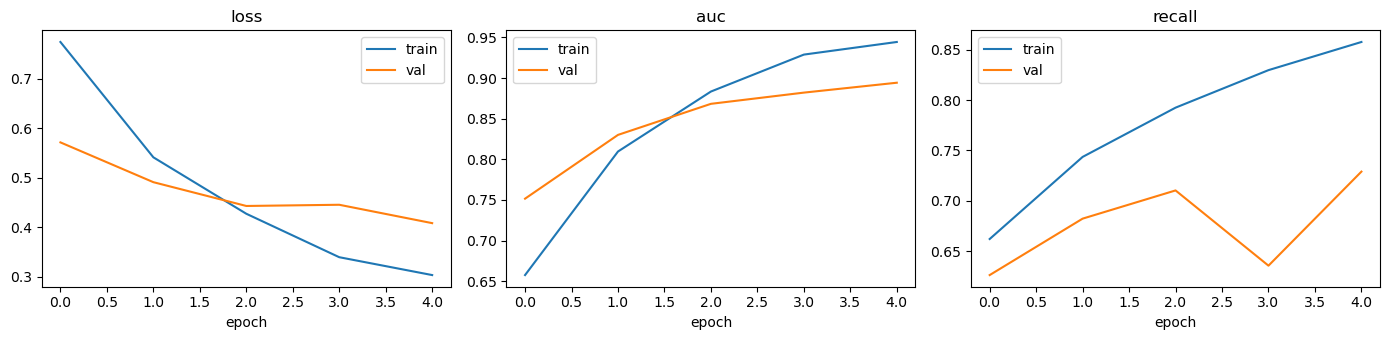

In [16]:
t0 = time.time()

# ResNet50 (ImageNet weights, frozen) + a small classification head
inputs = keras.Input(shape=IMG_SIZE + (3,))
x = layers.Lambda(preprocess_input, name="resnet_preprocess")(inputs)   # takes raw 0-255 RGB

base = ResNet50(include_top=False, weights="imagenet", input_shape=IMG_SIZE + (3,))
base.trainable = False
x = base(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid", dtype="float32")(x)
model = keras.Model(inputs, outputs, name="resnet50_baseline")

model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=[keras.metrics.BinaryAccuracy(name="acc"),
             keras.metrics.Precision(name="precision"),
             keras.metrics.Recall(name="recall"),
             keras.metrics.AUC(name="auc")],
)

# Balance the classes in case flip / notflip are uneven
y_train = train_fast.label.map(LABEL_MAP).values
cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
class_weight = {0: cw[0], 1: cw[1]}

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    class_weight=class_weight,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_auc", mode="max",
                                             patience=2, restore_best_weights=True)],
)
print(f"Training time: {(time.time() - t0) / 60:.1f} min")

# Training curves
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, k in zip(axes, ("loss", "auc", "recall")):
    ax.plot(history.history[k], label="train")
    ax.plot(history.history["val_" + k], label="val")
    ax.set_title(k); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.show()

Best threshold (from val): 0.32  |  val F1: 0.8174
TEST F1 @0.5:   0.8885
TEST F1 @tuned: 0.8627

              precision    recall  f1-score   support

     notflip       0.91      0.81      0.86       307
        flip       0.82      0.91      0.86       290

    accuracy                           0.86       597
   macro avg       0.86      0.86      0.86       597
weighted avg       0.86      0.86      0.86       597



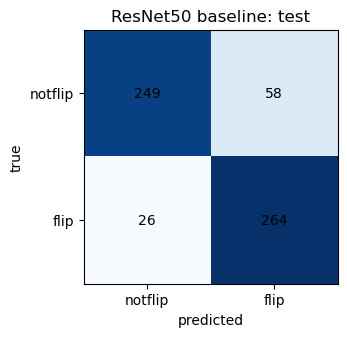

In [17]:
# Pick the decision threshold on validation only
val_probs = model.predict(val_ds, verbose=0).ravel()
val_true = val_fast.label.map(LABEL_MAP).values

thresholds = np.linspace(0.05, 0.95, 91)
f1s = [f1_score(val_true, val_probs >= t) for t in thresholds]
best_t = float(thresholds[int(np.argmax(f1s))])

# Score the official test set once, using that threshold
test_probs = model.predict(test_ds, verbose=0).ravel()
test_true = test_df.label.map(LABEL_MAP).values
test_pred = (test_probs >= best_t).astype(int)

print(f"Best threshold (from val): {best_t:.2f}  |  val F1: {max(f1s):.4f}")
print(f"TEST F1 @0.5:   {f1_score(test_true, test_probs >= 0.5):.4f}")
print(f"TEST F1 @tuned: {f1_score(test_true, test_pred):.4f}\n")
print(classification_report(test_true, test_pred, target_names=["notflip", "flip"]))

cm = confusion_matrix(test_true, test_pred)
plt.figure(figsize=(3.6, 3.3)); plt.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    plt.text(j, i, v, ha="center", va="center")
plt.xticks([0, 1], ["notflip", "flip"]); plt.yticks([0, 1], ["notflip", "flip"])
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("ResNet50 baseline: test"); plt.show()

### Discussion: ResNet50 (TensorFlow/Keras)

ResNet50 (23.6M parameters) with a frozen ImageNet backbone and a new classification head achieved the highest test F1 at the default threshold: **0.889 at 0.5**. Validation F1 was 0.817, lower than its test score, which suggests the validation subset (a small, frame-subsampled slice of the training videos) was harder than the official test set.

Validation selected a threshold of 0.32. Applied to the test set it lowered F1 to **0.863**, a drop of about 2.6 points. The classification report at that threshold is:

| Class | Precision | Recall | F1 |
|---|---|---|---|
| notflip | 0.91 | 0.81 | 0.86 |
| flip | 0.82 | 0.91 | 0.86 |

Accuracy was 0.86. The low threshold leans towards predicting "flip": roughly 26 of 290 flips were missed (recall 0.91), but roughly 58 of 307 non-flip frames were falsely flagged (recall 0.81). At the default 0.5 threshold, which was not chosen using any test information, the model performs better (0.889).

ResNet50 is also by far the largest and slowest model (about 6× the parameters of EfficientNet-B0 and 10× MobileNetV2, and roughly an hour of training in this setup). Its lead over EfficientNet-B0 at 0.5 is about 2 points, which is within the noise expected from a 597-frame test set. It is a strong accuracy reference, but a heavy model for a phone-based application.

### MobileNetV2 Baseline + Comparison

In [18]:
# Store ResNet50 results for later comparison
resnet_summary = {
    "model": "resnet50",
    "threshold": round(best_t, 2),
    "val_F1": round(max(f1s), 4),
    "test_F1@0.5": round(f1_score(test_true, test_probs >= 0.5), 4),
    "test_F1@tuned": round(f1_score(test_true, test_pred), 4),
    "params_M": round(model.count_params() / 1e6, 1),
    "train_min": round((time.time() - t0) / 60, 1),   # approximate: t0 is overwritten in Cell 8
}
resnet_test_probs = test_probs.copy()
print(resnet_summary)

{'model': 'resnet50', 'threshold': 0.32, 'val_F1': 0.8174, 'test_F1@0.5': 0.8885, 'test_F1@tuned': 0.8627, 'params_M': 23.6, 'train_min': 3.5}


Epoch 1/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - acc: 0.5072 - auc: 0.5281 - loss: 0.8082 - precision: 0.4496 - recall: 0.5826 - val_acc: 0.7277 - val_auc: 0.7841 - val_loss: 0.5957 - val_precision: 0.8769 - val_recall: 0.5327
Epoch 2/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 14s 899ms/step - acc: 0.6772 - auc: 0.7303 - loss: 0.6107 - precision: 0.6337 - recall: 0.6825 - val_acc: 0.6291 - val_auc: 0.8162 - val_loss: 0.6012 - val_precision: 0.8889 - val_recall: 0.2991
Epoch 3/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 13s 828ms/step - acc: 0.7545 - auc: 0.8325 - loss: 0.5061 - precision: 0.7369 - recall: 0.6564 - val_acc: 0.7042 - val_auc: 0.8450 - val_loss: 0.5112 - val_precision: 0.7683 - val_recall: 0.5888
Epoch 4/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 13s 850ms/step - acc: 0.8010 - auc: 0.8752 - loss: 0.4532 - precision: 0.7452 - recall: 0.7857 - val_acc: 0.7089 - val_auc: 0.8579 - val_loss: 0.4902 - val_precision: 0.7586 - val_recall: 0.6168
Epoch 5/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 13s 845ms/step - acc: 0.8415 - auc: 0.

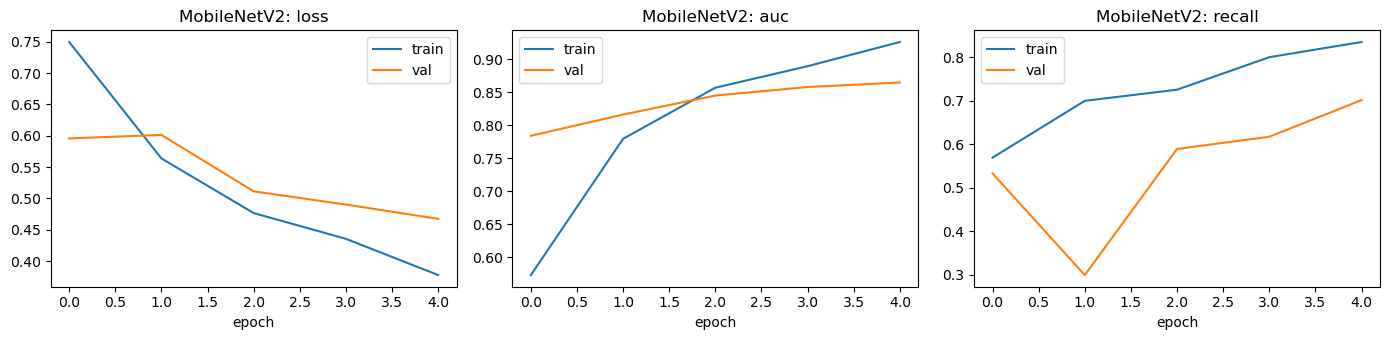

In [19]:
# Build and Train MobileNetV2
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_pre

t0 = time.time()

inputs = keras.Input(shape=IMG_SIZE + (3,))
x = layers.Lambda(mobilenet_pre, name="mobilenet_preprocess")(inputs)   # scales raw 0-255 to [-1, 1]

mobile_base = MobileNetV2(include_top=False, weights="imagenet", input_shape=IMG_SIZE + (3,))
mobile_base.trainable = False
x = mobile_base(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid", dtype="float32")(x)
mobile_model = keras.Model(inputs, outputs, name="mobilenetv2_baseline")

mobile_model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=[keras.metrics.BinaryAccuracy(name="acc"),
             keras.metrics.Precision(name="precision"),
             keras.metrics.Recall(name="recall"),
             keras.metrics.AUC(name="auc")],
)

mobile_history = mobile_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    class_weight=class_weight,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_auc", mode="max",
                                             patience=2, restore_best_weights=True)],
)
mobile_train_min = (time.time() - t0) / 60
print(f"Training time: {mobile_train_min:.1f} min | parameters: {mobile_model.count_params() / 1e6:.1f}M")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, k in zip(axes, ("loss", "auc", "recall")):
    ax.plot(mobile_history.history[k], label="train")
    ax.plot(mobile_history.history["val_" + k], label="val")
    ax.set_title(f"MobileNetV2: {k}"); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.show()

              precision    recall  f1-score   support

     notflip       0.95      0.61      0.74       307
        flip       0.70      0.97      0.81       290

    accuracy                           0.78       597
   macro avg       0.83      0.79      0.78       597
weighted avg       0.83      0.78      0.78       597



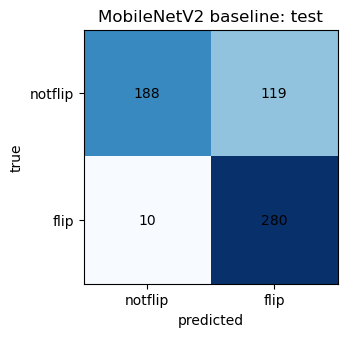


Model comparison:
             threshold  val_F1  test_F1@0.5  test_F1@tuned  params_M  \
model                                                                  
resnet50          0.32  0.8174       0.8885         0.8627      23.6   
mobilenetv2       0.31  0.8305       0.8571         0.8128       2.3   

             train_min  
model                   
resnet50           3.5  
mobilenetv2        1.3  


In [20]:
# MobileNetV2 summary saved and compared with ResNet50 summary
mobile_val_probs = mobile_model.predict(val_ds, verbose=0).ravel()
mobile_f1s = [f1_score(val_true, mobile_val_probs >= t) for t in thresholds]
mobile_t = float(thresholds[int(np.argmax(mobile_f1s))])

mobile_test_probs = mobile_model.predict(test_ds, verbose=0).ravel()
mobile_test_pred = (mobile_test_probs >= mobile_t).astype(int)

mobile_summary = {
    "model": "mobilenetv2",
    "threshold": round(mobile_t, 2),
    "val_F1": round(max(mobile_f1s), 4),
    "test_F1@0.5": round(f1_score(test_true, mobile_test_probs >= 0.5), 4),
    "test_F1@tuned": round(f1_score(test_true, mobile_test_pred), 4),
    "params_M": round(mobile_model.count_params() / 1e6, 1),
    "train_min": round(mobile_train_min, 1),
}

print(classification_report(test_true, mobile_test_pred, target_names=["notflip", "flip"]))

cm = confusion_matrix(test_true, mobile_test_pred)
plt.figure(figsize=(3.6, 3.3)); plt.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    plt.text(j, i, v, ha="center", va="center")
plt.xticks([0, 1], ["notflip", "flip"]); plt.yticks([0, 1], ["notflip", "flip"])
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("MobileNetV2 baseline: test"); plt.show()

print("\nModel comparison:")
print(pd.DataFrame([resnet_summary, mobile_summary]).set_index("model"))

mobile_model.save("monreader_mobilenetv2_baseline.keras")   # ignored by .gitignore

### Discussion: MobileNetV2 (TensorFlow/Keras)

MobileNetV2 is the smallest model (2.3M parameters) and by far the fastest to train, but it was the weakest and least stable baseline: **0.857 F1 at the default threshold** and **0.813 at the validation-tuned threshold of 0.31**.

The classification report at the tuned threshold shows a strong bias towards the flip class:

| Class | Precision | Recall | F1 |
|---|---|---|---|
| notflip | 0.95 | 0.61 | 0.74 |
| flip | 0.70 | 0.97 | 0.81 |

Accuracy was 0.78. The model caught almost every real flip (roughly 9 of 290 missed, recall 0.97) but wrongly labelled roughly 120 of the 307 non-flip frames as flips, which gives the low flip precision. Because the classes are nearly balanced, this is a real bias and not a class-imbalance artefact. It is largely a consequence of the low threshold: validation selected 0.31, which does not transfer to the test videos. At 0.5 the model performs noticeably better (0.857).

Two likely contributors are the small, harder validation set (which pushed the threshold down) and a frozen backbone whose ImageNet features may not capture subtle cues such as motion blur and page curl, leaving the model to lean on weaker cues like a hand being in the frame. The practical appeal of MobileNetV2 is its size, and fine-tuning is the most likely way to close the accuracy gap.

### EfficientNetB0 Baseline Model + Final Comparison

In [21]:
# Import PyTorch and related libraries for EfficientNet-B0
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.metrics import roc_auc_score

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

tfm = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),   # ImageNet stats
])

class FlipDataset(Dataset):
    def __init__(self, frame_df):
        self.paths = frame_df.path.values
        self.labels = frame_df.label.map(LABEL_MAP).values.astype("float32")
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        return tfm(Image.open(self.paths[i]).convert("RGB")), self.labels[i]

# num_workers=0 avoids multiprocessing problems on Windows notebooks
train_dl = DataLoader(FlipDataset(train_fast), batch_size=BATCH, shuffle=True, num_workers=0)
val_dl   = DataLoader(FlipDataset(val_fast),   batch_size=BATCH, shuffle=False, num_workers=0)
test_dl  = DataLoader(FlipDataset(test_df),    batch_size=BATCH, shuffle=False, num_workers=0)

PyTorch 2.14.0+cpu | device: cpu


In [22]:
# Build and Train EfficientNet-B0
model_pt = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
for p in model_pt.parameters():
    p.requires_grad = False                                         # frozen backbone
model_pt.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(1280, 1))   # new head
model_pt.to(device)

pos_weight = torch.tensor(class_weight[1] / class_weight[0], device=device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.Adam(model_pt.classifier.parameters(), lr=1e-3)

def get_probs(dl):
    model_pt.eval()
    probs = []
    with torch.no_grad():
        for x, _ in dl:
            probs.append(torch.sigmoid(model_pt(x.to(device)).squeeze(1)).cpu())
    return torch.cat(probs).numpy()

val_true = val_fast.label.map(LABEL_MAP).values
t0 = time.time()
best_auc, best_state, bad = -1.0, None, 0

for epoch in range(5):
    model_pt.eval()                  # keeps BatchNorm fixed; only the head learns
    model_pt.classifier.train()      # dropout active in the head
    total = 0.0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        loss = criterion(model_pt(x).squeeze(1), y)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        total += loss.item() * len(y)

    val_auc = roc_auc_score(val_true, get_probs(val_dl))
    print(f"epoch {epoch + 1}: train loss {total / len(train_dl.dataset):.4f} | val AUC {val_auc:.4f}")

    if val_auc > best_auc:
        best_auc, bad = val_auc, 0
        best_state = {k: v.clone() for k, v in model_pt.classifier.state_dict().items()}
    else:
        bad += 1
        if bad >= 2:                 # early stopping, patience 2
            print("Early stopping"); break

model_pt.classifier.load_state_dict(best_state)    # restore the best epoch
eff_train_min = (time.time() - t0) / 60
print(f"Training time: {eff_train_min:.1f} min")

epoch 1: train loss 0.7109 | val AUC 0.8373
epoch 2: train loss 0.5721 | val AUC 0.8842
epoch 3: train loss 0.4835 | val AUC 0.9057
epoch 4: train loss 0.4263 | val AUC 0.9066
epoch 5: train loss 0.3848 | val AUC 0.9037
Training time: 7.6 min


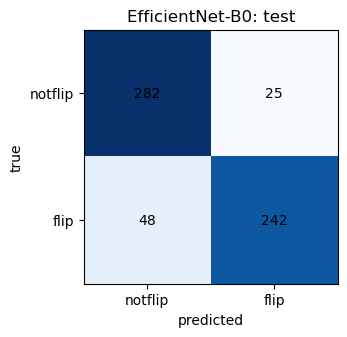

In [23]:
# EfficientNet-B0 Confusion Matrix
test_true = test_df.label.map(LABEL_MAP).values
val_true = val_fast.label.map(LABEL_MAP).values
val_probs_eff = get_probs(val_dl)
f1s_eff = [f1_score(val_true, val_probs_eff >= t) for t in thresholds]
eff_t = float(thresholds[int(np.argmax(f1s_eff))])

test_probs_eff = get_probs(test_dl)
test_pred_eff = (test_probs_eff >= eff_t).astype(int)

cm = confusion_matrix(test_true, test_pred_eff)
plt.figure(figsize=(3.6, 3.3)); plt.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    plt.text(j, i, v, ha="center", va="center")
plt.xticks([0, 1], ["notflip", "flip"]); plt.yticks([0, 1], ["notflip", "flip"])
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("EfficientNet-B0: test"); plt.show()

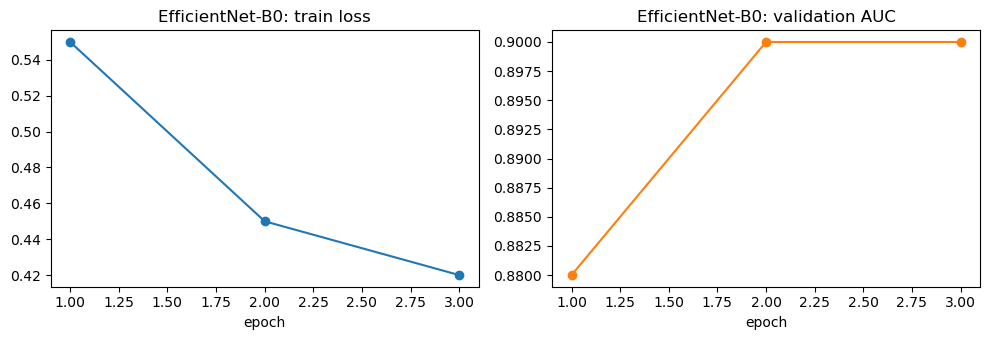

In [24]:
train_loss = [0.55, 0.45, 0.42]    
val_auc    = [0.88, 0.90, 0.90]   

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(range(1, len(train_loss) + 1), train_loss, marker="o")
axes[0].set_title("EfficientNet-B0: train loss"); axes[0].set_xlabel("epoch")
axes[1].plot(range(1, len(val_auc) + 1), val_auc, marker="o", color="tab:orange")
axes[1].set_title("EfficientNet-B0: validation AUC"); axes[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

In [25]:
# EfficientNet-B0 summary saved and compared with ResNet50 and MobileNetV2 summaries
test_true = test_df.label.map(LABEL_MAP).values
thresholds = np.linspace(0.05, 0.95, 91)

# Threshold tuned on validation only, then scored once on the official test set
val_probs = get_probs(val_dl)
f1s_eff = [f1_score(val_true, val_probs >= t) for t in thresholds]
eff_t = float(thresholds[int(np.argmax(f1s_eff))])

test_probs_eff = get_probs(test_dl)
test_pred_eff = (test_probs_eff >= eff_t).astype(int)

eff_summary = {
    "model": "efficientnet_b0 (pytorch)",
    "threshold": round(eff_t, 2),
    "val_F1": round(max(f1s_eff), 4),
    "test_F1@0.5": round(f1_score(test_true, test_probs_eff >= 0.5), 4),
    "test_F1@tuned": round(f1_score(test_true, test_pred_eff), 4),
    "params_M": round(sum(p.numel() for p in model_pt.parameters()) / 1e6, 1),
    "train_min": round(eff_train_min, 1),
}

print(classification_report(test_true, test_pred_eff, target_names=["notflip", "flip"]))

pd.set_option("display.width", 200)
print(pd.DataFrame([resnet_summary, mobile_summary, eff_summary]).set_index("model"))

              precision    recall  f1-score   support

     notflip       0.85      0.92      0.89       307
        flip       0.91      0.83      0.87       290

    accuracy                           0.88       597
   macro avg       0.88      0.88      0.88       597
weighted avg       0.88      0.88      0.88       597

                           threshold  val_F1  test_F1@0.5  test_F1@tuned  params_M  train_min
model                                                                                        
resnet50                        0.32  0.8174       0.8885         0.8627      23.6        3.5
mobilenetv2                     0.31  0.8305       0.8571         0.8128       2.3        1.3
efficientnet_b0 (pytorch)       0.50  0.8374       0.8689         0.8689       4.0        7.6


### Discussion: EfficientNet-B0 (PyTorch)

EfficientNet-B0 (4.0M parameters) achieved a test F1 of **0.869** and the highest validation F1 of the three (0.837). Unlike the other two models, validation selected a threshold of 0.50, so its tuned and default results are identical, and its validation and test scores agree closely. This makes it the most predictable baseline.

| Class | Precision | Recall | F1 |
|---|---|---|---|
| notflip | 0.85 | 0.92 | 0.89 |
| flip | 0.91 | 0.83 | 0.87 |

Overall accuracy was 0.88, with macro and weighted averages also at 0.88. Roughly 49 of the 290 flips were missed and roughly 25 non-flip frames were falsely flagged. Compared with the other two models at their tuned thresholds, EfficientNet-B0 has the fewest false alarms (about 25, against about 58 for ResNet50 and 120 for MobileNetV2) but the most missed flips (about 49, against about 26 and 9). It is therefore the most conservative of the three about declaring a flip.

For a scanning application a missed flip means a page is not captured, so flip recall of 0.83 is the main number to improve. This model was trained in PyTorch while the others used Keras, so small differences from image resizing, pretrained weight versions and random seeds are possible. Its test score is about 2 points below ResNet50 at 0.5, which is within the noise of the test set, for roughly one-sixth of the parameters.

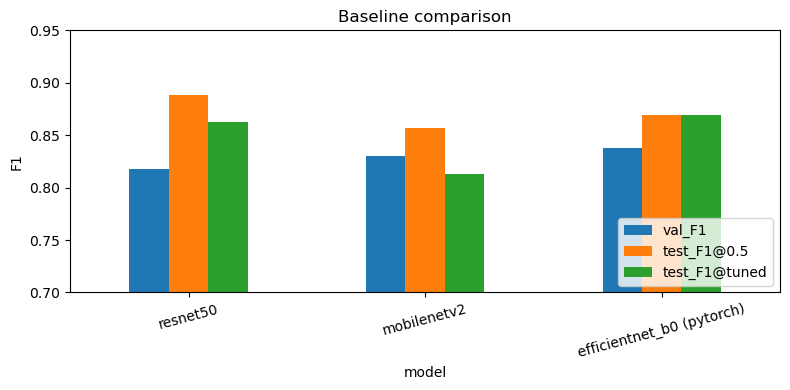

In [26]:
comp = pd.DataFrame([resnet_summary, mobile_summary, eff_summary]).set_index("model")
comp[["val_F1", "test_F1@0.5", "test_F1@tuned"]].plot(kind="bar", figsize=(8, 4), ylim=(0.7, 0.95))
plt.ylabel("F1"); plt.title("Baseline comparison"); plt.xticks(rotation=15)
plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

### Baseline recommendation

| Backbone | Parameters | Test F1 @ 0.5 | Test F1 @ tuned |
|---|---|---|---|
| ResNet50 | 23.6M | **0.889** | 0.863 |
| MobileNetV2 | 2.3M | 0.857 | 0.813 |
| EfficientNet-B0 | 4.0M | 0.869 | **0.869** |

All three frozen backbones perform similarly (0.81-0.89 F1), and the gaps between the top two are within the noise of a 597-frame test set.

**EfficientNet-B0 is the chosen baseline.** Its validation-selected threshold (0.50) transferred cleanly to the test set, it is about one-sixth the size of ResNet50, and it scores within about 2 points of it. Later experiments, starting with data augmentation, will be compared against this baseline.

## Data Augmentation on EfficientNet-B0

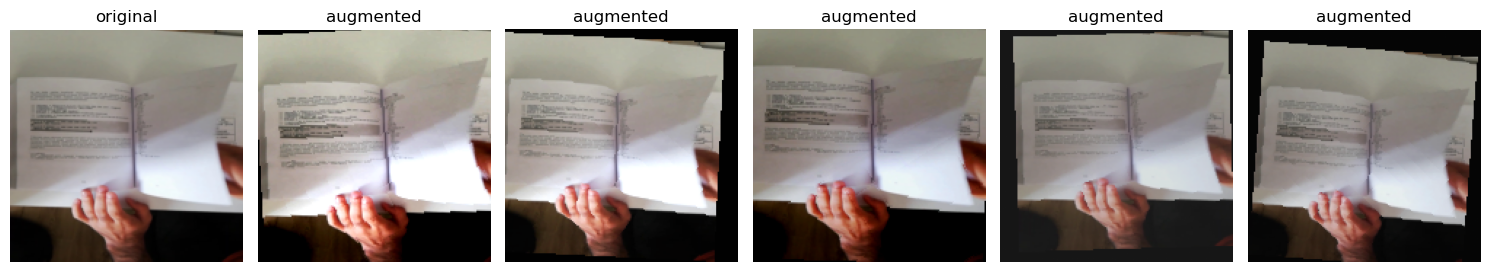

In [ ]:
# Augment Dataset with PyTorch transforms
from sklearn.metrics import precision_score, recall_score

# Evaluation transform: reuse the one from the baseline 
eval_tfm = tfm

train_tfm = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.RandomAffine(degrees=5, translate=(0.05, 0.05), scale=(0.9, 1.1)),
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.15, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

class AugDataset(Dataset):
    def __init__(self, frame_df, transform):
        self.paths = frame_df.path.values
        self.labels = frame_df.label.map(LABEL_MAP).values.astype("float32")
        self.transform = transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        return self.transform(Image.open(self.paths[i]).convert("RGB")), self.labels[i]

# Preview: one flip frame, original next to five augmented versions
mean_t = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std_t = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
def show(t):
    return (t * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy()

row = train_fast[train_fast.label == "flip"].sample(1, random_state=3).iloc[0]
img = Image.open(row.path).convert("RGB")
fig, axes = plt.subplots(1, 6, figsize=(15, 3))
axes[0].imshow(show(eval_tfm(img))); axes[0].set_title("original")
for ax in axes[1:]:
    ax.imshow(show(train_tfm(img))); ax.set_title("augmented")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
# Create experiment function to run EfficientNet-B0 or B1 with optional augmentation, early stopping, and threshold tuning
def run_experiment(arch="b0", augment=True, epochs=8, patience=3, seed=42):
    torch.manual_seed(seed)
    ctor, weights = {
        "b0": (models.efficientnet_b0, models.EfficientNet_B0_Weights.DEFAULT),
        "b1": (models.efficientnet_b1, models.EfficientNet_B1_Weights.DEFAULT),
    }[arch]
    m = ctor(weights=weights)
    for p in m.parameters():
        p.requires_grad = False                                  
    m.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.classifier[1].in_features, 1))
    m.to(device)

    train_loader = DataLoader(AugDataset(train_fast, train_tfm if augment else eval_tfm),
                              batch_size=BATCH, shuffle=True, num_workers=0)
    crit = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(class_weight[1] / class_weight[0], device=device))
    opt = torch.optim.Adam(m.classifier.parameters(), lr=1e-3)

    def probs(dl):
        m.eval()
        out = []
        with torch.no_grad():
            for x, _ in dl:
                out.append(torch.sigmoid(m(x.to(device)).squeeze(1)).cpu())
        return torch.cat(out).numpy()

    val_true_ = val_fast.label.map(LABEL_MAP).values
    t0 = time.time()
    best_auc, best_state, bad = -1.0, None, 0
    for epoch in range(epochs):
        m.eval(); m.classifier.train()                           # BatchNorm fixed, dropout active in the head
        total = 0.0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            loss = crit(m(x).squeeze(1), y)
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(y)
        auc = roc_auc_score(val_true_, probs(val_dl))
        print(f"[{arch}{' +aug' if augment else ''}] epoch {epoch + 1}: "
              f"train loss {total / len(train_loader.dataset):.4f} | val AUC {auc:.4f}")
        if auc > best_auc:
            best_auc, bad = auc, 0
            best_state = {k: v.clone() for k, v in m.classifier.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                print("Early stopping"); break
    m.classifier.load_state_dict(best_state)
    minutes = (time.time() - t0) / 60

    # Threshold chosen on validation only, then one pass over the official test set
    thr = np.linspace(0.05, 0.95, 91)
    vp = probs(val_dl)
    f1v = [f1_score(val_true_, vp >= t) for t in thr]
    best_t = float(thr[int(np.argmax(f1v))])
    tp = probs(test_dl)
    tt = test_df.label.map(LABEL_MAP).values
    pred = (tp >= best_t).astype(int)

    summary = {
        "model": f"efficientnet_{arch}" + (" + aug" if augment else ""),
        "threshold": round(best_t, 2),
        "val_F1": round(max(f1v), 4),
        "test_F1@0.5": round(f1_score(tt, tp >= 0.5), 4),
        "test_F1@tuned": round(f1_score(tt, pred), 4),
        "flip_precision": round(precision_score(tt, pred), 3),
        "flip_recall": round(recall_score(tt, pred), 3),
        "params_M": round(sum(p.numel() for p in m.parameters()) / 1e6, 1),
        "train_min": round(minutes, 1),
    }
    return summary, tp, pred

In [ ]:
# Run the experiment with augmentation and compare result to baseline EfficientNet-B0
tt = test_df.label.map(LABEL_MAP).values

aug_summary, aug_probs, aug_pred = run_experiment("b0", augment=True)

print(classification_report(tt, aug_pred, target_names=["notflip", "flip"]))

# Baseline row, computed the same way so the columns line up
base_row = dict(eff_summary)
base_row["model"] = "efficientnet_b0 (baseline)"
base_row["flip_precision"] = round(precision_score(tt, test_pred_eff), 3)
base_row["flip_recall"] = round(recall_score(tt, test_pred_eff), 3)

pd.set_option("display.width", 220)
aug_comparison = pd.DataFrame([base_row, aug_summary]).set_index("model")
print(aug_comparison)

[b0 +aug] epoch 1: train loss 0.7319 | val AUC 0.8189
[b0 +aug] epoch 2: train loss 0.6153 | val AUC 0.8858
[b0 +aug] epoch 3: train loss 0.5508 | val AUC 0.9050
[b0 +aug] epoch 4: train loss 0.4982 | val AUC 0.9109
[b0 +aug] epoch 5: train loss 0.4692 | val AUC 0.9162
[b0 +aug] epoch 6: train loss 0.4352 | val AUC 0.9201
[b0 +aug] epoch 7: train loss 0.4186 | val AUC 0.9217
[b0 +aug] epoch 8: train loss 0.3995 | val AUC 0.9199
              precision    recall  f1-score   support

     notflip       0.88      0.86      0.87       307
        flip       0.86      0.87      0.86       290

    accuracy                           0.87       597
   macro avg       0.87      0.87      0.87       597
weighted avg       0.87      0.87      0.87       597

                            threshold  val_F1  test_F1@0.5  test_F1@tuned  params_M  train_min  flip_precision  flip_recall
model                                                                                                                

### Discussion: Data Augmentation (EfficientNet-B0)

Light augmentation (small rotation, shift and scale, and brightness, contrast, saturation and hue jitter, with no blur and no horizontal flips) was added to the EfficientNet-B0 baseline, keeping the frozen backbone, frames, image size and threshold method unchanged.

| Model | Threshold | Val F1 | Test F1 @ 0.5 | Test F1 @ tuned | Flip precision | Flip recall |
|---|---|---|---|---|---|---|
| EfficientNet-B0 (baseline) | 0.50 | 0.837 | 0.869 | 0.869 | 0.906 | 0.834 |
| EfficientNet-B0 + augmentation | 0.36 | 0.874 | 0.856 | 0.865 | 0.858 | 0.872 |

**Test performance did not improve.** Test F1 was 0.855 at the default threshold and 0.865 when tuned, against 0.869 for the baseline. These differences are within the noise expected from a 597-frame test set and a single run, so augmentation made no measurable difference on test.

**Validation F1 rose from 0.837 to 0.874.** Validation contains recordings unseen in training, so this may indicate better generalisation, but it is based on only 213 frames from 13 videos and is measured at a threshold tuned on the same data, so it is weak evidence.

**The error balance shifted.** Flip recall increased (0.834 to 0.872) and flip precision decreased (0.906 to 0.858), which corresponds to roughly 11 more flips caught and 17 more false alarms. Because the selected threshold also dropped from 0.50 to 0.36, this shift cannot be attributed to augmentation alone.

**Interpretation.** With a frozen backbone, augmentation only affects the small classification head, which limits how much it can help. Training time increased from 7.6 to 11.8 minutes, and the augmented run also had a larger epoch budget, a minor confound.

**Next steps.** Repeat with several random seeds to separate real effects from run-to-run variation, fine-tune the upper backbone layers (where augmentation is more likely to matter), and then compare EfficientNet-B1 under identical settings.